# Case study 3: detecting the active power source

You are the data scientist nLine asked for. GridWatch sensors in Sierra Leone hospitals report voltage and frequency every two minutes. They do not report whether the load is on **grid**, **solar**, or **generator**. The existing system labels that with hand-written rules. This notebook replaces the fragile parts of those rules with a time-series pipeline, checks it properly, and leaves a model behind an API.

The written method is specific to today's hospitals (a Princess Christian rule, an Ola During rule, a hand-picked grid reference). A model that only memorizes those names will not travel. The pipeline below keeps the domain features, then asks several algorithms which ones actually separate the classes.

Set `RETRAIN = True` in the training cell when you want to rebuild every artifact. The cells under it read the artifacts that are already in `case_study_3/artifacts`, so the room can discuss results without refitting.

The next two sections are the idea, on eight made-up readings: what a time series is, then what the sktime package is for. The hospital extract starts after that.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ronnie-Leon76/Kamilimu-2026-DS/blob/case-study-3-pipeline/Deploying%20ML%20Solutions/case_study_3_detecting_generator_usage.ipynb)


## Time series, for the first time

A time series is a measurement written down again and again, in time order. In this case the measurement is a hospital sensor: voltage and frequency, usually every two minutes, for about a year. One row is one moment. The next row is the next moment for the same sensor.

The order is part of the data. In an ordinary table, two people's heights can swap places and the table still means the same thing. Swap 14:00 and 14:10 on a sensor and you have invented a power cut that did not happen.

Here are eight made-up readings from one afternoon. The clock is the index. The number is frequency in hertz. Mains power in Sierra Leone sits near 50 Hz.

| Time | Hz |
| --- | --- |
| 14:00 | 50.0 |
| 14:02 | 50.0 |
| 14:04 | 50.1 |
| 14:06 | 49.9 |
| 14:08 | 47.4 |
| 14:10 | 47.6 |
| 14:12 | 47.5 |
| 14:14 | 47.3 |

Up to 14:06 the line is calm and close to 50. At 14:08 it steps down and stays down. A generator often looks like that step: the frequency leaves 50 Hz and keeps moving. Grid and solar tend to sit in a tight band around 50. The step is visible because the rows stayed in order. A shuffled table would only report that some values sit near 50 and some sit near 47.

Three rules follow from that. The rest of this notebook is those rules applied to 5.1 million rows.

**The recent past describes the present.** The source at 14:08 depends on 14:00 through 14:06 as well as on the reading at 14:08. A lone 47.4 could be a glitch. A drop that stays down is a change of source. The trailing mean and the trailing spread, built later, are summaries of that recent past.

**The future stays unused.** A live sensor naming the source at 14:08 does not yet have 14:10. A model trained on the next few minutes scores well in a notebook and then fails when a phone asks what is on right now. The features behind the API look backward only. One rule baseline looks about six minutes ahead. It is scored so you can see it, and it is not the model that gets deployed.

**Time is not shuffled.** Random cross-validation can train on 14:10 and test on 14:08. The model has then already seen the neighbour of the moment it is supposed to meet for the first time. The honest split is a cut on the calendar: train on everything before a date, test on everything after it. The February 2024 holdout is that cut.

The same file supports two questions, and they stay separate.

- **Classification** asks what is on at this moment: grid, solar, or generator. The input is a short window of recent readings. The output is a label.
- **Forecasting** asks what the frequency will be later. The input is the history up to now. The output is the next stretch of the same series.

A classifier that answers "generator" has not forecast the next hour. A forecast of 47.5 Hz has not named the source. Both appear later, in their own sections, and the scores are kept apart.


## The sktime package

scikit-learn treats each row as a vector of columns. You call `fit`, then `predict`. That is the right shape for "these 24 summary numbers, which source?". It is an awkward shape for "this sequence, what comes next?" and for "this whole window is one example".

[sktime](https://www.sktime.net/) is the time-series library that keeps the scikit-learn habit and adds the clock. You still call `fit` and `predict`. The objects also know a forecasting horizon, a seasonal period, and a stack of windows. This notebook uses sktime 1.2. The forecasting section follows the [sktime forecasting tutorial](https://www.sktime.net/docs/examples/forecasting/).

You will meet two families. Both show up again on the hospital data. This section only introduces the objects, on the eight-point afternoon above.

**Forecasters** answer "what will this series do next?".

- `NaiveForecaster` is the baseline everyone else has to beat. `strategy="last"` repeats the latest value. On an hourly series, `sp=24` repeats yesterday's same hour. A fancier model that loses to this baseline is not earning its place.
- `ForecastingHorizon` is the list of future steps you want, counted forward from the last training time.
- `make_reduction` wraps an ordinary scikit-learn regressor, ridge regression in this notebook, so that it can forecast. It slides a window along the past, predicts the next step, and feeds that prediction back in.
- `mean_absolute_error` scores a forecast in the units of the series. For frequency, that unit is hertz.
- `ExpandingWindowSplitter` grows the past, tests on the next slice, then grows again. One lucky fortnight is then not the whole result.

The hospital version is [Forecasting with sktime](#forecasting-with-sktime): one room, hourly mean frequency, a 14-day horizon.

**Window classifiers** answer "what label does this short series carry?". One example is no longer one row of columns. One example is 16 time steps of voltage and frequency, about half an hour. sktime stacks many of those examples into a panel shaped `(windows, channels, time)`.

- `RocketClassifier` runs many random sliding patterns over each window, then a linear classifier.
- A time-series forest cuts the raw frequency series into random intervals.
- A summary classifier is the control: mean, standard deviation, and the other cheap summaries of the window, then an ordinary model.

Those three are scored in [Classifying the raw window with sktime](#classifying-the-raw-window-with-sktime). On this extract the hand-built features still win, and the API serves that boosting model. sktime is here so the comparison is visible.

The cell below is the whole forecaster API on the made-up afternoon: a series with a clock, a horizon of three steps, `fit`, `predict`. The forecast repeats the last value the model was allowed to see. Later cells are the same four ideas on a year of hospital readings.


What was fit, in `pipeline/train.py`, on the training windows only:

- Windows are length **16** (about half an hour). **1,500 per class** for training, **500 per class** for the holdout table (1,500 windows, balanced).
- `SummaryClassifier` sees both channels, voltage and frequency. It is the control: cheap summaries, then an ordinary classifier.
- `TimeSeriesForestClassifier(n_estimators=50)` sees **frequency only**. That implementation rejects a multivariate array. In the panel, voltage is channel 0 and frequency is channel 1.
- `RocketClassifier(num_kernels=1000)` sees both channels. The cell under the table refits ROCKET on 600 windows with 200 kernels so you can watch `fit` return. The table is the 1,000-kernel fit.

On this run, macro F1 on those 1,500 windows: boosting on the engineered row 0.970, summary classifier 0.863, time-series forest 0.856, LSTM 0.824, RNN 0.750, ROCKET 0.493. ROCKET losing to the summary classifier is the result. Sixteen points is a short series, and the trailing MAD already extracted the part a threshold can use.


## Run this on Google Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ronnie-Leon76/Kamilimu-2026-DS/blob/case-study-3-pipeline/Deploying%20ML%20Solutions/case_study_3_detecting_generator_usage.ipynb)

Colab receives this notebook and nothing else. The next cell clones the public repository, which carries `pipeline/`, `service/`, the tests, and the saved `artifacts/`. Run it before the sktime cell. On a laptop that already has this repository, the cell does nothing.

The 789 MB extract is not in that repository. Leave `RETRAIN = False` and the later cells read the cloned artifacts. To retrain, upload `labeled_power_source_data.csv` to Drive, mount Drive, and set `POWER_SOURCE_CSV` to that file before the audit cell.


In [1]:
import os
import sys
import subprocess
from pathlib import Path

# Colab opens this .ipynb alone. The clone brings pipeline/, service/, tests/, and artifacts/.
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Ronnie-Leon76/Kamilimu-2026-DS.git"
BRANCH = "case-study-3-pipeline"
CLONE = Path("/content/Kamilimu-2026-DS")

if IN_COLAB:
    package = CLONE / "Deploying ML Solutions" / "case_study_3" / "pipeline" / "config.py"
    if not package.exists():
        subprocess.check_call([
            "git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(CLONE),
        ])
    os.chdir(CLONE)
    requirements = CLONE / "Deploying ML Solutions" / "case_study_3" / "requirements.txt"
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(requirements)])
    print("repository:", CLONE)
    print("pipeline:", package.parent)
    print("artifacts:", CLONE / "Deploying ML Solutions" / "case_study_3" / "artifacts")
else:
    print("Not Colab. Using the pipeline folder already on this machine.")


Not Colab. Using the pipeline folder already on this machine.


In [2]:
import warnings
import pandas as pd
from sktime.forecasting.base import ForecastingHorizon
from sktime.forecasting.naive import NaiveForecaster

# sktime 1.3 will change a storage default. The fit below is unaffected.
warnings.filterwarnings("ignore", message="The default of config")

clock = pd.date_range("2024-03-21 14:00", periods=8, freq="2min")
frequency = pd.Series(
    [50.0, 50.0, 50.1, 49.9, 47.4, 47.6, 47.5, 47.3],
    index=clock,
    name="Hz",
)
print("the whole afternoon")
print(frequency)

past = frequency.iloc[:-3]
horizon = ForecastingHorizon([1, 2, 3], is_relative=True)
forecaster = NaiveForecaster(strategy="last")
forecaster.fit(past)
forecast = forecaster.predict(horizon)
print("trained through", past.index[-1].strftime("%H:%M"), "on", float(past.iloc[-1]), "Hz")
print("forecast for the three stamps the model was not shown:")
print(forecast)


the whole afternoon
2024-03-21 14:00:00    50.0
2024-03-21 14:02:00    50.0
2024-03-21 14:04:00    50.1
2024-03-21 14:06:00    49.9
2024-03-21 14:08:00    47.4
2024-03-21 14:10:00    47.6
2024-03-21 14:12:00    47.5
2024-03-21 14:14:00    47.3
Freq: 2min, Name: Hz, dtype: float64
trained through 14:08 on 47.4 Hz
forecast for the three stamps the model was not shown:
2024-03-21 14:10:00    47.4
2024-03-21 14:12:00    47.4
2024-03-21 14:14:00    47.4
Freq: 2min, Name: Hz, dtype: float64


## What you will produce

1. A row ledger that proves every record in the extract was read.
2. Features a live service can compute without looking into the future.
3. A principal-component view of those features.
4. Temporal cross-validation, then a February–March 2024 holdout.
5. sktime forecasters and sktime classifiers, plus a small RNN and LSTM.
6. Generator, grid, and solar hours for every room.
7. The chosen model behind `POST /predict`, in Docker, called the way a web or mobile app would call it.
8. A SHAP explanation of the boosting model: which feature moved each class probability, globally and for one window of each class.
9. A joblib walkthrough: save a fitted model, load it back, and see what `model.joblib` actually contains.

An 8 GB laptop can run the cached path in this notebook. A full rebuild of the 5.1 million rows is more comfortable on Kaggle. Use [`case_study_3/kaggle_power_source.ipynb`](case_study_3/kaggle_power_source.ipynb) and the case-study README for the click-by-click version.


## Why earlier attempts stopped near 2.1 million rows

The extract has **5,125,181** data rows and a header. Two ordinary tools throw most of them away:

- Excel's worksheet limit is 1,048,576 rows. Two sheets are 2,097,152 rows, which is the "about 2.1 million" figure.
- `pd.read_csv` on the 789 MB file builds one object-dtype frame. On an 8 GB laptop that allocation dies, and whatever is left in memory is again a couple of million rows.

The loader in `pipeline/load.py` counts newlines, parses with an explicit schema and `on_bad_lines="error"` (it is not allowed to skip a bad line), and writes one parquet file per sensor. There are 35 sensors. Later steps never hold more than one sensor's history. If the count is not 5,125,181, training stops.


In [3]:
from pathlib import Path
import sys

def locate_case_dir() -> Path:
    cwd = Path.cwd().resolve()
    bases = [cwd, *cwd.parents, Path("/content/Kamilimu-2026-DS")]
    for base in bases:
        for candidate in (base / "case_study_3", base / "Deploying ML Solutions" / "case_study_3"):
            if (candidate / "pipeline").exists():
                return candidate
    raise FileNotFoundError("Open this notebook from the repository, or run the Colab clone cell.")

CASE_DIR = locate_case_dir()
if str(CASE_DIR) not in sys.path:
    sys.path.insert(0, str(CASE_DIR))

from pipeline.config import EXPECTED_DATA_ROWS, FEATURE_COLUMNS, TWO_EXCEL_SHEETS
from pipeline.load import audit_csv

try:
    ledger = audit_csv()
except FileNotFoundError as exc:
    print(exc)
    print("No extract in this session. RETRAIN stays False and the cells below use artifacts/.")
    print("To audit the file, set POWER_SOURCE_CSV to labeled_power_source_data.csv and rerun this cell.")
else:
    print(f"newline count says {ledger['data_rows_from_newlines']:,} data rows")
    print(f"expected {EXPECTED_DATA_ROWS:,}")
    print(f"two Excel sheets would have been {TWO_EXCEL_SHEETS:,}")
    print("match" if ledger["matches_expected"] else "MISMATCH")

[17:19:51] newline audit: 5,125,181 data rows (794 MB), expected 5,125,181
newline count says 5,125,181 data rows
expected 5,125,181
two Excel sheets would have been 2,097,152
match


## Train, or load the run that is already on disk

`python -m pipeline.train` from `case_study_3` does the full job: partition, features, PCA, models, holdout, figures, `model.joblib`. The first run takes a while because it reads the extract once and then walks the 35 sensor files several times. A second run reuses `case_study_3/work`.

`RETRAIN = False` below loads that run. It does not hide the fit. The cells further down print the hyperparameters out of `model.joblib` and the per-class holdout scores out of `metrics.json`. The recipe, which is what `pipeline/train.py` actually runs, is written in the Models section.

Order of the fit, once the 35 sensor files exist:

1. `StandardScaler.partial_fit` on every pre-holdout row, one sensor at a time.
2. `IncrementalPCA(n_components=10)` on those scaled rows.
3. Two epochs of `SGDClassifier.partial_fit`, on the scaled features and again on the ten components.
4. Gradient boosting on a balanced sample of 40,000 rows per class. Random forest on 8,000 per class of that sample.
5. Three calendar folds on a thinned pre-holdout sample. This is a check, not the model that gets saved.
6. RNN, LSTM, and the three sktime classifiers on the 16-step windows.
7. Score every model on all 947,085 holdout rows. Pick the winner. Then permutation importance, the hourly forecast, the room hours, and SHAP.

The saved run finished in about four minutes after the csv was already on disk, on 15 October 2026, with scikit-learn 1.9.0.


In [4]:
import json
import pandas as pd
from IPython.display import Image, display

RETRAIN = False
if RETRAIN:
    from pipeline.train import run
    run(force_rebuild=True)

ARTIFACTS = CASE_DIR / "artifacts"
FIGURES = ARTIFACTS / "figures"
metrics = json.loads((ARTIFACTS / "metrics.json").read_text(encoding="utf-8"))
eda = json.loads((ARTIFACTS / "eda_summary.json").read_text(encoding="utf-8"))
print("rows in the feature store:", f"{metrics['rows_in_feature_store']:,}")
print("duplicate timestamps collapsed:", metrics["duplicate_timestamps_collapsed"])
print("holdout starts:", metrics["holdout_start"], "rows:", f"{metrics['holdout_rows']:,}")
print("deployed strategy:", metrics["default_strategy"])
print("label counts:", metrics["label_counts"])
print("median gap seconds:", eda["gap_seconds"]["p50"], "share of gaps over 10 min:", round(eda["gap_seconds"]["share_over_10_min"], 4))

rows in the feature store: 5,125,181
duplicate timestamps collapsed: 0
holdout starts: 2024-02-01T00:00:00Z rows: 947,085
deployed strategy: hybrid_hgb
label counts: {'generator': 547765, 'grid': 2403874, 'solar': 2160602, 'unknown': 12940}
median gap seconds: 120.0 share of gaps over 10 min: 0.0023


## What the labels actually are

`active_power_source` is the output of the current rule system, not a meter on the generator. High accuracy against it means "we can reproduce the rules", which is useful, and it is not an independent audit of which machine was really running. `unknown` (a few tens of thousands of rows, often a dead voltage near 2 V or a nonsense frequency near 99 Hz) is kept in the exploratory counts and left out of supervised training.

The interesting rooms are the ones with more than one source installed. A solar-only room does not need a model. The comparison table below therefore reports macro F1 on all rooms and again on multi-source rooms only. Macro F1 gives generator a vote even though it is the smallest class. Generator recall is the fuel-and-carbon number.


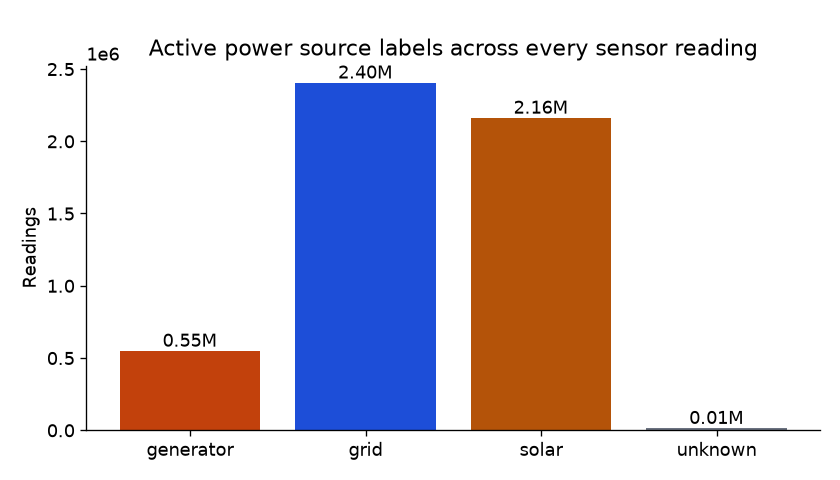

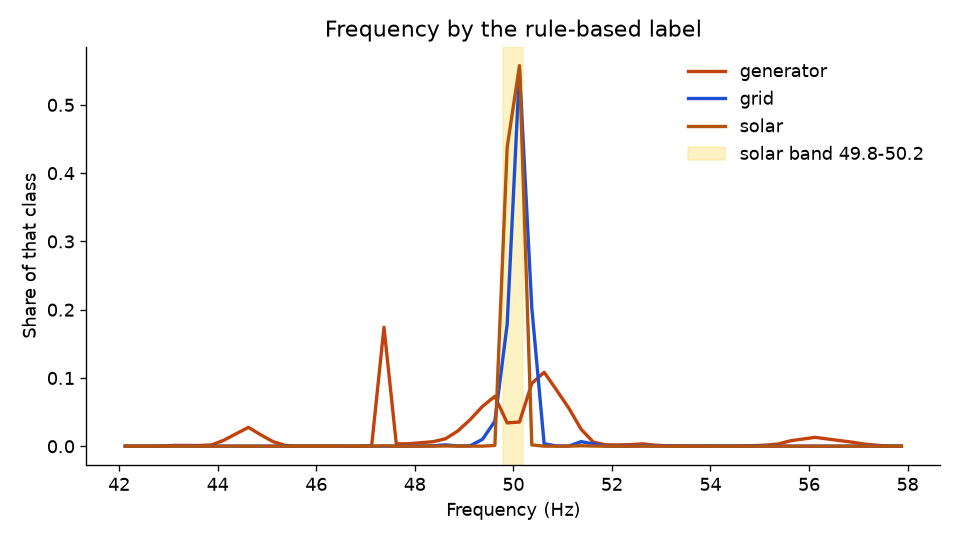

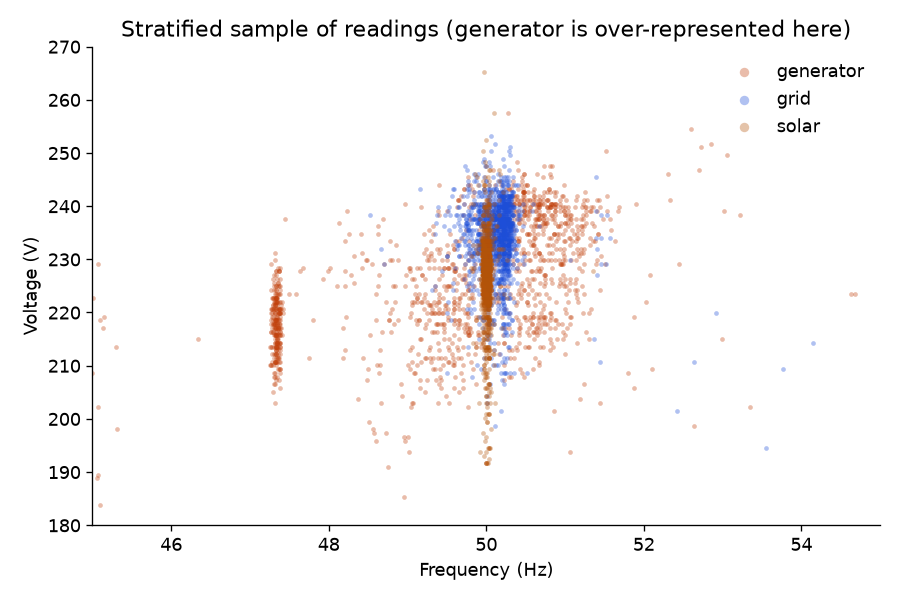

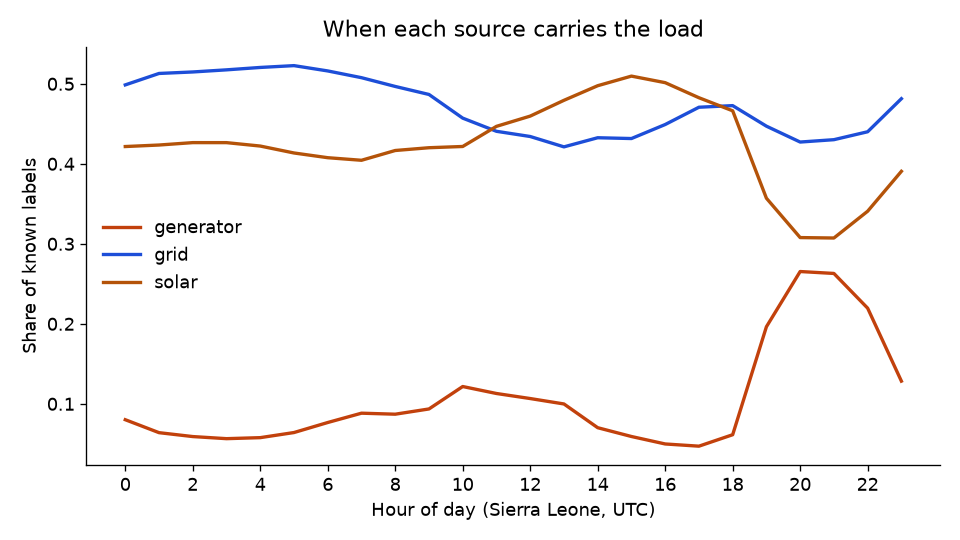

In [5]:
display(Image(filename=str(FIGURES / "class_balance.png")))
display(Image(filename=str(FIGURES / "frequency_by_source.png")))
display(Image(filename=str(FIGURES / "voltage_frequency.png")))
display(Image(filename=str(FIGURES / "hour_of_day.png")))

### How to read the pictures

Solar sits in a tight band around 50 Hz. Grid is near 50 Hz with a wider spread. Generator is the wide one: the note's range of roughly 43–57 Hz is visible, and so are the glitch readings out at the edges. The scatter is stratified, so generator is drawn more often than it occurs; use the bar chart for the base rate. The hour-of-day chart is the operational one: solar carries the daytime load where it is installed, and generator fills evenings and outages.

Low voltage (under 50 V) is the closest thing in this extract to the "null frequency means outage" sentence in the note. Those rows are rare and are mostly labelled `unknown`.


## Features: turning a clock into columns

Feature engineering is deciding which numbers a model is allowed to see. It is performed in this order.

1. **Name the decision.** Here the decision is the power source at one two-minute stamp, for one sensor. One row in the model table is that stamp. It is not the whole day, and it is not the whole hospital.
2. **Write the questions a careful engineer would ask, in the sensor's own units.** Is the frequency near 50 Hz? Did it just jump? Has the last ten minutes been quiet? Is this room different from the rest of the hospital at this same minute? What equipment is installed? What hour is it?
3. **Turn each question into a formula that can be computed at that stamp.** A formula that needs the next reading leaks the future. It scores well in a notebook and fails when a phone asks what is on right now. The formula also has to be computable from the JSON the API receives, so training and the service share one function, `engineer_sensor`.
4. **Check the formula on a handful of rows you can do by hand.** The cell under this section is that check. A flat 50 Hz line must have a trailing MAD of 0. If it does not, the formula is wrong, and there is no point running it on 5.1 million rows.
5. **Run it on the extract only after that check passes.**
6. **Ask which columns are the same fact written more than once.** That question is principal component analysis, in the next section.

A logistic model, a random forest, and gradient boosting all expect one row of numbers. A sensor gives a clock. The six steps above are the translation. At each moment, write down a fixed set of numbers that describe that moment and the recent past, and hand that row to the model.

Take the afternoon from the opening section, at 14:08, when frequency has just fallen from 49.9 Hz to 47.4 Hz.

- The raw frequency is 47.4. That is one column.
- Distance from the nominal 50 Hz is 2.6. The model can then cut on "far from 50" directly.
- The jump from the previous reading is 47.4 − 49.9 = −2.5. A calm stretch has a jump near zero. A source switch has a large one.
- The trailing window is this reading plus the ones just before it, up to seven points, which is about twelve minutes when the sensor is reporting every two minutes. Right at the step, the mean of that window is still near 50, because most of the window has not fallen yet. The minimum has already fallen. A few minutes later the low values fill the window and the mean falls too. The spread of the window is the "is this stretch quiet?" evidence the solar rule wants.
- The site median is the typical frequency of the sensors in that hospital during the same two minutes. A room at 47.4 while the rest of the site sits at 50 has left the site. A room at 47.4 while every room is at 47.4 means the whole site has moved.

The pipeline writes 24 columns. They are that same idea, split into groups a mentee can check one at a time.

| Group | Columns | The picture |
| --- | --- | --- |
| The reading | `voltage`, `frequency` | The sensor at this minute |
| Distance from normal | `abs_freq_dev_50`, `abs_volt_dev_230` | How far from 50 Hz and from 230 V |
| The jump | `freq_diff_1`, `volt_diff_1` | This reading minus the previous one |
| The recent past | `trail_mean_freq`, `trail_std_freq`, `trail_mad_freq`, `trail_min_freq`, `trail_max_freq`, `trail_std_volt` | A trailing window of seven readings |
| The rest of the hospital | `freq_dev_site_median`, `n_sensors_in_bucket` | This room against the site, in the same two minutes |
| The clock | `hour_sin`, `hour_cos`, `dow_sin`, `dow_cos` | Hour of day and day of week, written on a circle |
| The survey | `has_grid`, `has_solar`, `has_generator`, `n_sources` | What is installed in the room |
| Trust | `gap_minutes`, `low_voltage` | A long silence, or voltage under 50 V |

A few of those need a sentence of their own.

**The window looks backward.** Every model feature at time *t* may use readings at *t* and earlier. A gap longer than 10 minutes ends the window: a missing hour is a new stretch, and the jump across that hole is stored as zero so it is not mistaken for a slow drift. The other sensors in the same two-minute bucket are allowed in, because they are measured at the same time. The case note would rather use a grid-only room as the reference. This extract has no grid-only room, so the reference is the median frequency of every sensor at that site in that bucket. `n_sensors_in_bucket` tells the model when that median is only the sensor looking at itself.

**MAD means the mean absolute deviation from the window mean.** On a flat 50 Hz stretch every point equals the mean, so MAD is 0. The solar rule treats a MAD of 0.1 or less, inside 49.8–50.2 Hz, as a quiet solar band. The case note computes that MAD on a centred window: three readings before and three after. The centred window can see about six minutes into the future. The cell below prints both. Watch the centred column move while the frequency is still exactly 50. The trailing column stays at 0 until the step arrives. The deployed models use the trailing column. The centred value is computed and then shown only to the "rules as written" baseline.

**The survey is already known at deployment.** `has_grid`, `has_solar`, and `has_generator` come from the installation string, not from the waveform. `n_sources` is how many of those three the room has. A single-source room is labelled from this survey before any frequency rule runs.

**Hour and weekday sit on a circle.** 23:00 and 00:00 are neighbours on a ward, and Sunday and Monday are neighbours on a calendar. Two sine and cosine columns keep that neighbourhood. A raw hour number would place 23 a long way from 0. Clock times in the file are Sierra Leone local time, which is UTC. Passing them through `datetime.fromtimestamp` on a laptop set to Nairobi shifts the hour by three, and the circle then describes the wrong part of the day.


In [6]:
import numpy as np
from pipeline.features import engineer_sensor

# Seven calm readings at 50 Hz, then a step to 46, a bounce to 55, and 48.
time_s = np.arange(10, dtype=np.int64) * 120
frequency = np.array([50, 50, 50, 50, 50, 50, 50, 46, 55, 48], dtype=float)
voltage = np.full(10, 230.0)
buckets = (time_s // 120) * 120
X, centered, site_median = engineer_sensor(
    time_s, voltage, frequency,
    np.ones(10), np.ones(10), np.ones(10),
    buckets, np.full(10, 50.0, np.float32), np.full(10, 3, np.float32),
)
show = [
    "frequency",
    "abs_freq_dev_50",
    "freq_diff_1",
    "trail_mean_freq",
    "trail_mad_freq",
    "trail_min_freq",
    "trail_max_freq",
]
view = pd.DataFrame(X, columns=FEATURE_COLUMNS).loc[[4, 6, 7, 9], show]
view.insert(1, "centered_mad", centered[[4, 6, 7, 9]])
view.index = ["still_50_but_future_knows", "last_flat_point", "the_step", "after_the_bounce"]
print(view.round(3))
print("feature count:", len(FEATURE_COLUMNS))

                           frequency  centered_mad  abs_freq_dev_50  \
still_50_but_future_knows       50.0         0.980              0.0   
last_flat_point                 50.0         1.633              0.0   
the_step                        46.0         1.889              4.0   
after_the_bounce                48.0         2.750              2.0   

                           freq_diff_1  trail_mean_freq  trail_mad_freq  \
still_50_but_future_knows          0.0        50.000000           0.000   
last_flat_point                    0.0        50.000000           0.000   
the_step                          -4.0        49.429001           0.980   
after_the_bounce                  -7.0        49.856998           1.633   

                           trail_min_freq  trail_max_freq  
still_50_but_future_knows            50.0            50.0  
last_flat_point                      50.0            50.0  
the_step                             46.0            50.0  
after_the_bounce            

### How to read that table

Four moments are enough.

- `still_50_but_future_knows` is still exactly 50 Hz. Trailing MAD is 0. Centred MAD has already left 0, because three readings ahead include the drop to 46. That column has peeked. It stays out of the deployed model.
- `last_flat_point` is the last calm reading. Distance from 50 is 0, the jump is 0, and the trailing window is a flat line, so its mean is 50 and its MAD is 0.
- `the_step` is the reading of 46 Hz. Distance from 50 is 4. The jump is −4. The trailing mean only slips to about 49.4, because six of the seven window points are still 50. The minimum is already 46, and trailing MAD leaves 0. The level of the window lags the event. The minimum and the jump do not.
- `after_the_bounce` is 48 Hz, and the reading just before it was 55. The jump column is 48 − 55 = −7. Distance from 50 is a different fact, and it is 2. The trailing max has risen to 55 because the bounce is now inside the window.

The feature count printed under the table is 24. Centred MAD is not one of them.


## Principal components: when several columns are one fact

Dimensionality reduction means describing each row with fewer numbers, on purpose. You keep most of how the rows differ from each other, and you accept throwing the rest away. Principal component analysis is the method this notebook uses to do that.

Picture two columns that say the same thing: a frequency, and a copy of that frequency with a tiny wobble. Plotted, the points form a thin line, not a round cloud. The long direction of the line is a new axis. A row's position on that axis is one score, and it carries what both columns were saying. The short direction, at right angles to the line, is the wobble. Dropping the wobble is the reduction: two numbers in, one number out.

The real table has 24 columns, and several of them are related rather than copies, so one score is not enough. Ten scores keep 86.87% of the scaled spread. The other 13% is the part we agree to drop when the logistic model named `sgd_pca` runs. The deployed boosting model does not drop it. It still sees all 24 columns, because a threshold in hertz is easier to defend than a threshold on a score.

The next cell is the two-column picture, small enough to read. The cell after it is the 24-column fit.

Twenty-four columns is a small table. The trouble is that several of them rise and fall together. Frequency, distance from 50 Hz, the trailing mean, and the trailing minimum are all descriptions of the same hertz. A logistic model has one weight per column. When four columns carry one signal, those weights split the signal in a way you cannot audit, and the fit gets brittle.

Principal component analysis draws a new set of axes through the cloud of rows.

1. **Scale first.** Each column is shifted to mean 0 and stretched to standard deviation 1. A frequency near 50 and a flag that is only 0 or 1 are then on speaking terms. Without that step the large numbers would decide the axes on their own.
2. **Find the long direction of the cloud.** The first component is the direction along which the rows spread out the most. The second is the next direction, at right angles to the first, so it describes something the first one left unexplained. Later components continue that way.
3. **Read a loading as "how hard this column pulls on this axis".** Each original column has a number on each component. A loading of 0.38 and a loading of −0.38 are equally strong. The size is the strength. The sign is which end of the axis the column sits on. Rank by the absolute value, which is what the cell below prints.
4. **Read the scree plot as "how much of the spread each axis keeps".** A tall first bar means one pattern dominates. A long flat tail means the later axes are small leftovers. The percentages are shares of variance after scaling.

The training fit uses incremental PCA: `partial_fit` on every pre-holdout row, ten components. Those ten keep **86.87%** of the scaled variance. The shares are about 18%, 14%, 11%, 8%, then several components near 6–7%, and a tenth near 3%. The curve flattens. The picture is a few strong patterns followed by milder ones.

The logistic model named `sgd_pca` sees only those ten scores. It is the experiment that asks whether the repeated hertz columns can be folded together. On the holdout its generator recall is 0.46, against 0.60 for the logistic model that still sees the original columns. Folding the hertz columns together makes the generator threshold harder to apply. The columns are related, and the decision still wants the original hertz.

Trees skip this step. A tree can cut on `abs_freq_dev_50` and leave a duplicate column unused. The cut stays in hertz, so you can compare it with the 0.11 Hz and 0.1 MAD sentences in the case note. A cut on "component 3 above 0.4" cannot be checked that way. The permutation-importance chart later shows which original columns the boosting model actually uses.

The scree image is that full incremental fit. The loadings printed underneath are a fresh PCA on the smaller teaching sample, so the notebook can show you the axes without another pass over 5.1 million rows. Use the sample to see which columns travel together. Use 86.87% as the figure from the real fit.


In [7]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Two columns that are one fact: a frequency, and the same frequency plus a tiny wobble.
# Dimensionality reduction asks whether those two numbers can become one score.
freq = np.array([50.0, 50.2, 49.8, 47.0, 46.2, 48.5, 54.0, 53.1])
almost_the_same = freq + np.array([0.04, -0.03, 0.02, 0.08, -0.05, 0.01, -0.06, 0.03])
pair = np.column_stack([freq, almost_the_same])
pair_scaled = StandardScaler().fit_transform(pair)
mini = PCA(n_components=2, random_state=0).fit(pair_scaled)
print("share of the spread kept by each component:", mini.explained_variance_ratio_.round(4))
print("how hard each column pulls on PC1:", mini.components_[0].round(3))
print("one score per row:", mini.transform(pair_scaled)[:, 0].round(2))

share of the spread kept by each component: [9.999e-01 1.000e-04]
how hard each column pulls on PC1: [0.707 0.707]
one score per row: [ 0.09  0.19 -0.02 -1.58 -2.06 -0.75  2.31  1.83]


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

display(Image(filename=str(FIGURES / "pca_scree.png")))
print("cumulative variance in the 10 deployed components:", metrics["pca_cumulative"])

sample = np.load(ARTIFACTS / "teaching_sample.npz")
scaler = StandardScaler().fit(sample["X"])
pca = PCA(n_components=10, random_state=0).fit(scaler.transform(sample["X"]))
loading = pd.DataFrame(pca.components_[:3].T, index=FEATURE_COLUMNS, columns=["PC1", "PC2", "PC3"])
print("largest |loadings| on the first component:")
print(loading["PC1"].abs().sort_values(ascending=False).head(6).round(3))

### How to read the scree plot and the loadings

The bars of the scree plot are the ten shares above, drawn for the full pre-holdout fit. The first three bars are the ones worth naming. After that the bars are similar in height, which is why keeping ten components still leaves about 13% of the variance behind, and why stopping at two would throw away patterns the logistic model might have used.

On the teaching sample the printout usually looks like this. Yours will match if the artifact has not been rebuilt.

- **PC1** is the hertz story plus the dead-sensor flag. The largest loadings sit on the trailing maximum, `low_voltage`, trailing MAD, the trailing mean, trailing spread, and frequency itself. One axis has gathered "how high and how wild is this stretch of frequency?".
- **PC2** mixes the trailing minimum, voltage, and `has_grid`. Level of frequency is still in there. This axis is no longer only the waveform.
- **PC3** is mostly the survey and the site: `has_grid`, `n_sources`, and how many sensors reported in the bucket. The rotation really does separate "what the frequency is doing" from "what equipment the room has".

That separation is the reason PCA is in the lesson. It is also the reason the deployed model keeps the original columns: the generator call in this case is a threshold on hertz, and a threshold is easier to defend in the original units.


## Models

| Model | What it sees | Why it is here |
| --- | --- | --- |
| Rules, centred MAD | The written cascade, including 6 minutes of future | The baseline the note describes. Not deployable live. |
| Rules, trailing MAD | The same cascade, causal | The baseline a service can actually run. |
| SGD logistic | All pre-holdout rows, two passes, class-balanced sample weights | Online learning. `partial_fit` is what `POST /online/update` calls later. |
| SGD + 10 principal components | Same rows, after incremental PCA | Checks whether the raw features were redundant. |
| HistGradientBoosting | 40,000 rows per class, stratified | Strong non-linear tabular model that still fits in laptop memory. |
| Random forest | 8,000 rows per class | A second tree algorithm, cheaper to explain. |
| Hybrid | Boosting or SGD, then the single-source rule and the PCMH / Ola During smoothing | The note asks what a hybrid would look like. |
| sktime summary, time-series forest, ROCKET | Raw 16-step windows of voltage and frequency | The series itself, with no hand-built MAD. |
| RNN and LSTM | The same windows | The sequence models. Weights are NumPy so the API does not need TensorFlow. |

sktime's `LSTMFCNClassifier` needs TensorFlow and `LSTMFCNClassifierTorch` needs PyTorch. Both are the right next step on a GPU machine. On the 8 GB laptops in this class they are the wrong dependency, so the notebook trains the same two ideas directly and the equations are in `pipeline/sequence_models.py`.

The holdout is every reading from **2024-02-01** onward. Nothing in `fit` is allowed to see those rows. Cross-validation, below, is only inside the earlier period.


## What was actually fit

Mentees who did this challenge fit models themselves and then argued about the numbers. This section is that argument, with the settings written down. The code that ran is `pipeline/train.py`. The notebook does not refit 5.1 million rows in class. It opens the objects that fit produced.

### Who is allowed to see which rows

`unknown` is out of every `fit` and every score. The label is often a dead sensor, about 2 V or a frequency near 99 Hz. There are 12,940 of those rows. They stay in the ledger.

The holdout is every known-label row with `time >= 2024-02-01` UTC: **947,085 rows**. No `fit` call receives them. Pre-holdout class counts, the rows the models may learn from, are generator 536,491, grid 2,052,703, solar 1,575,962. Generator is about one row in eight. A model that always says "grid" still looks accurate. That is why the selection metric is macro F1, and why generator recall is printed beside it.

### Logistic regression, on every pre-holdout row

This is the online model, so it has to be able to `partial_fit` one sensor file at a time. Nothing here loads all 4 million training rows as one frame.

- `StandardScaler.partial_fit` walks every pre-holdout row once.
- Scaled values are clipped to **[−8, 8]**. A glitch at 99 Hz would otherwise set the scale for the whole year.
- `IncrementalPCA(n_components=10, batch_size=4096)` is fit on those clipped rows. Ten components keep 86.87% of the variance.
- `SGDClassifier(loss="log_loss", penalty="l2", alpha=1e-4, average=True, max_iter=1)` is the logistic model. `log_loss` is logistic regression. `average=True` means the stored coefficients are a running average, which is why one classroom label later moves them by about `1e-7`.
- The same classifier is fit a second time on the 10 PCA scores (`sgd_pca`).
- Both see **two epochs**. Each row's sample weight is `n / (3 × count of its class)`, so generator, grid, and solar pull equally.
- After the fit, `classes_` must be `[0, 1, 2]`. That is generator, grid, solar. A shuffled class order would silently swap the API probabilities.

### Trees, on a balanced sample

Boosting and the forest do not stream. They also do not see all 4 million rows: a balanced draw is enough, and it stops generator from being a rounding error.

- Gradient boosting: **40,000 rows per class** (120,000 rows). `HistGradientBoostingClassifier(learning_rate=0.08, max_iter=120, max_depth=8, min_samples_leaf=30, l2_regularization=0.1)`. No scaling and no PCA. The cuts stay in hertz.
- Random forest: **8,000 rows per class** drawn from that same pool (24,000 rows). `RandomForestClassifier(n_estimators=40, max_depth=12, min_samples_leaf=5, n_jobs=1)`.

The holdout score still uses all 947,085 rows. The sample is only for `fit`.

### How the winner is chosen

`rules_centered` is scored and then excluded. It uses three readings after the current one. A live service does not have them.

Among the rest, the winner is the highest **macro F1 on multi-source rooms**, with overall macro F1 as the tie break. Single-source rooms are mostly the survey. A model can look strong there without having learned frequency.

On this run that rule selects **`hybrid_hgb`**: overall macro F1 **0.9385**, multi-source macro F1 **0.9364**, generator recall **0.9856**, accuracy 0.947. Plain boosting is 0.9355 / 0.9348 / 0.9856. The forest recalls generator slightly more often (0.9878) and loses on macro F1. The logistic model is close on macro F1 (0.8553) and weak on generator recall (0.6018). PCA logistic drops generator recall to 0.4566. The centred rules reach macro F1 0.8636 with generator recall 0.975 and generator precision only about 0.57: they call generator often, and they are often wrong when they do.

The cell after the comparison chart prints precision, recall, and support for every class, and it prints `get_params()` from the saved estimators so the numbers above can be checked against the file.


In [ ]:
comparison = pd.DataFrame(metrics["comparison"]).sort_values("multi_macro_f1", ascending=False)
comparison

In [ ]:
display(Image(filename=str(FIGURES / "model_comparison.png")))
display(Image(filename=str(FIGURES / "confusion_matrix.png")))
display(Image(filename=str(FIGURES / "permutation_importance.png")))
print("top permutation drops (macro F1):")
for name, value in list(metrics["permutation_importance"].items())[:8]:
    print(f"  {name:24s} {value}")

In [ ]:
import joblib

print("rows the learners were allowed to see, by class:")
print(metrics["train_class_counts"])
print("holdout rows:", f"{metrics['holdout_rows']:,}", " starting", metrics["holdout_start"])
print()

show = ["hybrid_hgb", "hgb", "rf", "rules_trailing", "rules_centered", "sgd", "sgd_pca"]
for name in show:
    block = metrics["holdout"][name]
    overall = block["overall"]
    multi = block["multi_source"]["macro_f1"]
    print(f"{name:16s}  macro F1 {overall['macro_f1']:.4f}   multi-source macro F1 {multi:.4f}   generator recall {overall['generator_recall']:.4f}")
    for label, row in overall["per_class"].items():
        print(f"    {label:10s}  precision {row['precision']:.3f}  recall {row['recall']:.3f}  f1 {row['f1']:.3f}  support {row['support']:,}")
    print()

bundle = joblib.load(ARTIFACTS / "model.joblib")
wanted = {
    "hgb": ["learning_rate", "max_iter", "max_depth", "min_samples_leaf", "l2_regularization"],
    "rf": ["n_estimators", "max_depth", "min_samples_leaf", "n_jobs"],
    "sgd": ["loss", "penalty", "alpha", "average", "max_iter"],
}
print("hyperparameters stored in model.joblib")
for name, keys in wanted.items():
    params = bundle[name].get_params()
    print(name, {key: params[key] for key in keys}, " classes_", list(bundle[name].classes_))
print("PCA components:", bundle["pca"].n_components_, " cumulative variance:", round(float(metrics["pca_cumulative"]), 4))


## SHAP: which feature moved this probability

Permutation importance answers "if I shuffle this column, how much does macro F1 fall?". SHAP answers a different question, one window at a time: how much did this feature push the probability of generator, grid, or solar up or down.

The figure explains the **boosting model**, which is the part of the hybrid that actually looks at the sensors. Tree SHAP cannot emit class probabilities for multiclass `HistGradientBoostingClassifier` yet, so these are permutation SHAP values of `predict_proba`. A positive value raised that class's probability. The background rows are from the training sample. The dots are holdout rows the model did not fit.

If the figures are missing, run `python -m pipeline.shap_analysis` from `case_study_3`. Training already calls that step when `shap` is installed.

In [ ]:
summary_path = ARTIFACTS / "shap_summary.json"
if not summary_path.exists():
    print("No SHAP summary yet. From case_study_3 run: python -m pipeline.shap_analysis")
else:
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    print(summary["method"])
    print(f"explained {summary['rows_explained']} holdout rows, background {summary['background_rows']}")
    for name in ("shap_mean_abs.png", "shap_beeswarm_generator.png", "shap_dependence.png", "shap_waterfall.png"):
        display(Image(filename=str(FIGURES / name)))
    print("one local explanation per class (top features for the true class):")
    for example in summary["local_examples"]:
        print(example["true_label"], "base", example["base_probability"])
        for item in example["top_features"]:
            print(f"  {item['feature']:24s} value={item['value']:<10} shap={item['shap']}")


## Cross-validation

Random k-fold would train on Tuesday afternoon and test on Tuesday morning. The folds here are calendar cuts inside the pre-holdout sample: train on everything before the cut, test on the next slice, then move the cut forward. That is the classification version of sktime's expanding window. The February holdout is not one of these folds. It is scored once, after the models are fit, on every remaining row.


The folds are not the deployed model with a different calendar. They are a smaller copy, so the check finishes in class:

- The pre-holdout teaching sample is thinned to at most **30,000** rows.
- Logistic regression in the fold is `SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=30)`, after a `StandardScaler` fit on that fold's training rows only.
- Boosting in the fold is `HistGradientBoostingClassifier(learning_rate=0.1, max_iter=60, max_depth=6)`. Shallower and shorter than the 120-iteration model that gets saved.

The three cuts are train before 2023-08-01 and test through September, train before 2023-10-01 and test through November, train before 2023-12-01 and test through January 2024. On this run boosting macro F1 is 0.9649, then 0.9537, then 0.9482. Logistic is 0.9491, then 0.9283, then 0.9161. Both ease off as the cut moves forward. Neither collapses. The February holdout is scored once, afterwards, on every remaining row.


In [ ]:
pd.DataFrame(metrics["cv_folds"])

<a id="forecasting-with-sktime"></a>

## Forecasting with sktime

Classification answers "what is on right now". Forecasting answers "what will the frequency look like over the next day". The workflow is the one in the [sktime forecasting tutorial](https://www.sktime.net/docs/examples/forecasting/):

1. Put one sensor on a regular hourly index (mean frequency).
2. Hold out the last 14 days.
3. Set a forecasting horizon.
4. Fit a seasonal naive (`sp=24`, yesterday's hour) and a Ridge model reduced to regression with `make_reduction`.
5. Score both with `mean_absolute_error`.
6. Repeat on an `ExpandingWindowSplitter` so one lucky fortnight is not the whole story.

The cell below refits the two forecasters on the saved hourly series so you can see the API. The expanding-window means from the full run are printed from `metrics.json`.


In [ ]:
import numpy as np
import warnings
from sklearn.linear_model import Ridge
from sktime.forecasting.base import ForecastingHorizon
from sktime.forecasting.compose import make_reduction
from sktime.forecasting.naive import NaiveForecaster
from sktime.performance_metrics.forecasting import mean_absolute_error

warnings.filterwarnings("ignore", message="The default of config")
hourly = pd.read_csv(ARTIFACTS / "hourly_frequency.csv", index_col=0, parse_dates=True).squeeze("columns")
hourly.index.freq = pd.tseries.frequencies.to_offset("h")
y_train = hourly.iloc[:-24 * 14]
y_test = hourly.iloc[-24 * 14 :]
horizon = ForecastingHorizon(np.arange(1, len(y_test) + 1), is_relative=True)

naive = NaiveForecaster(strategy="last", sp=24)
naive.fit(y_train)
pred_naive = naive.predict(horizon)

ridge = make_reduction(Ridge(alpha=1.0), strategy="recursive", window_length=48)
ridge.fit(y_train)
pred_ridge = ridge.predict(horizon)

print("room:", metrics["forecast"]["room"], "at", metrics["forecast"]["site_id"])
print("refit MAE seasonal naive:", round(float(mean_absolute_error(y_test, pred_naive)), 4))
print("refit MAE ridge reduction:", round(float(mean_absolute_error(y_test, pred_ridge)), 4))
print("expanding-window MAE naive:", metrics["forecast"]["cv_mae_seasonal_naive"])
print("expanding-window MAE ridge:", metrics["forecast"]["cv_mae_ridge_reduction"])
print("folds:", metrics["forecast"]["expanding_window_folds"])
display(Image(filename=str(FIGURES / "frequency_forecast.png")))

<a id="classifying-the-raw-window-with-sktime"></a>

## Classifying the raw window with sktime

ROCKET turns each 16-step, 2-channel window into a large set of random convolutional features and then fits a linear classifier. The time-series forest does the same job with random intervals, on frequency alone, because that forest implementation is univariate. The summary classifier is the control: mean, standard deviation, and the other cheap summaries of the window.

These three are scored on the same held-out windows as the RNN, the LSTM, and gradient boosting. Do not compare those macro-F1 numbers with the full-holdout table above. The full table is every February–March row. This table is 1,500 held-out windows, balanced across the three classes. On this extract ROCKET does not beat the summary classifier: sixteen points is a short series, and the useful signal is already a threshold on frequency. That is why the deployed model keeps the engineered features.


What was fit, in `pipeline/train.py`, on the training windows only:

- Windows are length **16** (about half an hour). **1,500 per class** for training, **500 per class** for the holdout table (1,500 windows, balanced).
- `SummaryClassifier` sees both channels, voltage and frequency. It is the control: cheap summaries, then an ordinary classifier.
- `TimeSeriesForestClassifier(n_estimators=50)` sees **frequency only**. That implementation rejects a multivariate array. In the panel, voltage is channel 0 and frequency is channel 1.
- `RocketClassifier(num_kernels=1000)` sees both channels. The cell under the table refits ROCKET on 600 windows with 200 kernels so you can watch `fit` return. The table is the 1,000-kernel fit.

On this run, macro F1 on those 1,500 windows: boosting on the engineered row 0.970, summary classifier 0.863, time-series forest 0.856, LSTM 0.824, RNN 0.750, ROCKET 0.493. ROCKET losing to the summary classifier is the result. Sixteen points is a short series, and the trailing MAD already extracted the part a threshold can use.


In [ ]:
window_rows = []
for name, scores in metrics["window_holdout"].items():
    window_rows.append({"model": name, "macro_f1": scores["macro_f1"], "generator_recall": scores["generator_recall"], "n": scores["n"]})
pd.DataFrame(window_rows).sort_values("macro_f1", ascending=False)

In [ ]:
from sktime.classification.kernel_based import RocketClassifier

windows = np.load(ARTIFACTS / "windows_train.npz")
panel = np.transpose(windows["X"][:600], (0, 2, 1))  # (instances, channels, time)
rocket = RocketClassifier(num_kernels=200, random_state=0, n_jobs=1)
rocket.fit(panel, windows["y"][:600])
print("ROCKET fitted on 600 windows. A full fit is already in the table above.")
print("classes:", rocket.classes_)

## RNN and LSTM

Both networks read the window and classify from the **last** hidden state. The RNN is

$$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b)$$

The LSTM adds a memory cell and four gates (input, forget, candidate, output) so that a stable 50 Hz morning is not forgotten by the time the window reaches a sag. Forget-gate bias starts at 1, which is the usual trick that stops the cell emptying on the first epoch. Training is Adam on cross-entropy, with gradient clipping. A 15% slice of the **training** windows is used to keep the best epoch. The test windows are not used for that choice.

The loss curves should fall. If the LSTM does not beat gradient boosting on the window table, that is a result, not a failure: these series are short, the useful signal is a handful of thresholds, and a tree on the trailing MAD already has that signal in one column.


The fit, from `pipeline/sequence_models.py` and `_fit_sequences`:

- Hidden size **32**. Eight epochs. Minibatch 128. Adam. Gradients clipped at norm 5.
- RNN learning rate **0.01**. LSTM learning rate **0.005**. LSTM forget-gate bias starts at 1.
- **15% of the training windows** are held out inside the fit to keep the best epoch. The 1,500 test windows are not used for that choice.
- Cross-entropy on this run, epoch by epoch. RNN: 0.987, 0.920, 0.810, 0.644, 0.530, 0.451, 0.419, 0.419. LSTM: 0.960, 0.615, 0.500, 0.456, 0.433, 0.413, 0.386, 0.380. Both fall, then flatten. The LSTM's loss is lower. Its generator recall on the window holdout is still 0.690, against 0.994 for boosting on the same windows.


In [ ]:
display(Image(filename=str(FIGURES / "sequence_loss.png")))
print("final training loss RNN", round(metrics["sequence_train_loss"]["rnn"][-1], 4))
print("final training loss LSTM", round(metrics["sequence_train_loss"]["lstm"][-1], 4))

## Hours on each source

For each pair of consecutive readings in the holdout, the gap is charged to the label of the earlier reading and capped at 30 minutes. A sensor that goes quiet for six hours must not become six hours of generator time. The same gaps are charged once using the rule label and once using the deployed model.

This is the table nLine asked for: solar, generator, and grid duration by room. The figure sums generator hours by hospital.


In [ ]:
usage = pd.read_csv(ARTIFACTS / "usage_durations.csv")
print("holdout generator hours, rule labels:", round(usage["hours_generator_true"].sum(), 1))
print("holdout generator hours, deployed model:", round(usage["hours_generator_pred"].sum(), 1))
display(Image(filename=str(FIGURES / "generator_hours.png")))
usage.head(12)

## What a hybrid is, in this pipeline

1. If the survey says the room has only one source, use that source. The frequency rules are for rooms that can switch.
2. Otherwise trust the selected model.
3. At Princess Christian, drop a generator call while the site median is still within 0.5 Hz of 50 Hz and at least two sensors reported. The note says "only allow generator when the grid is off" and does not define "off". 0.5 Hz is this pipeline's assumption, and it is written down so it can be changed.
4. At Ola During, while that same grid-off test is true, a frequency inside 49.8–50.2 Hz is solar.

`adjusted_by_rules` on the API response is true when step 3 or 4 changed the model's label.


## joblib, a 101

Training builds Python objects: a boosting model full of trees, a logistic model full of coefficients, a scaler full of means and spreads. They live in RAM. Close the notebook and they are gone. The API that starts tomorrow, on another machine, needs those same objects.

**joblib writes a fitted Python object to a file and reads it back.**

```python
joblib.dump(model, "model.joblib")   # save
model = joblib.load("model.joblib")  # open
```

`dump` is save. `load` is open. The ending `.joblib` is only a name we chose. The file is binary. A text editor will not show you the trees.

JSON is the wrong box for this. JSON stores lists, strings, and numbers, which is why `metrics.json` is JSON. It cannot store a `HistGradientBoostingClassifier` and give you back a classifier with a `predict` method. The standard-library tool that can store a Python object is `pickle`. joblib is built on pickle. Its extra skill is large NumPy arrays: it writes each array as one block, instead of walking every number through the pickle stream. A boosting model is mostly arrays, so that is the skill this file needs. scikit-learn uses joblib for the same reason.

The cell below does the round trip on a toy, then opens the real artifact.

**What this project actually saves.** `pipeline/train.py` does not dump one estimator. It dumps a dictionary. The keys you should be able to point at are:

| Key | What it is |
| --- | --- |
| `hgb` | The gradient-boosting model |
| `rf` | The random forest |
| `sgd` | The logistic model, the one that can `partial_fit` |
| `sgd_pca` | The same kind of logistic model, on ten principal components |
| `scaler` | Means and spreads for the logistic models |
| `pca` | The incremental PCA |
| `classes` | `generator`, `grid`, `solar`, in that order |
| `feature_names` | The 24 columns, in the order the models saw them |
| `sklearn_version` | The scikit-learn that wrote the file |

The API calls `joblib.load` once, when the process starts, and keeps that dictionary. A request does not retrain.

Two smaller files sit next to it.

- `online_model_init.joblib` is the logistic model and its scaler, as training left them.
- `online_model.joblib` starts as a copy of that file. `POST /online/update` calls `partial_fit` and then `joblib.dump` so the update is still there after a restart. `POST /online/reset` loads the init file and dumps it back over the working copy. Feedback never rewrites `model.joblib`. The boosting model stays frozen.

The RNN and LSTM are not in these files. Their weights are NumPy arrays this project wrote by hand, so they are saved with `numpy.savez` as `lstm_weights.npz` and `rnn_weights.npz`. joblib is for the scikit-learn objects. `.npz` is for the arrays we own.

Three habits.

**Match the library version.** A file written by scikit-learn 1.9.0 is loaded with scikit-learn 1.9.0. The service pins that version. `sklearn_version` inside the dictionary is how you check.

**Load files this class produced.** A `.joblib` file is a pickle. Opening it runs the instructions in the file. That is what you want for `artifacts/model.joblib` from this training run. It is the wrong kind of file to open if a stranger emailed it to you.

**Travel with the companions.** The logistic model was fit on scaled columns. Saving `sgd` and leaving `scaler` behind would make every later score nonsense. The dictionary is how the pipeline keeps the model, the scaler, the PCA, and the column order in one file.


In [ ]:
import tempfile
import warnings
from pathlib import Path

import joblib
import numpy as np
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore", message="Setting the shape on a NumPy array")

# Four made-up minutes: calm 50 Hz is grid (1), a drop with a big deviation is generator (0).
toy_x = np.array([[50.0, 0.0], [50.1, 0.1], [47.0, 3.0], [46.5, 3.5]])
toy_y = np.array([1, 1, 0, 0])
toy = LogisticRegression().fit(toy_x, toy_y)
before = toy.predict(np.array([[47.2, 2.8]]))

toy_path = Path(tempfile.mkdtemp()) / "toy.joblib"
joblib.dump({"model": toy, "features": ["frequency", "abs_freq_dev_50"]}, toy_path)
restored = joblib.load(toy_path)
after = restored["model"].predict(np.array([[47.2, 2.8]]))
print("toy file:", toy_path.name, "bytes:", toy_path.stat().st_size)
print("prediction before dump:", int(before[0]), " after load:", int(after[0]))
print("coefficients survived:", np.allclose(toy.coef_, restored["model"].coef_))

real_path = ARTIFACTS / "model.joblib"
bundle = joblib.load(real_path)
print("real file MB:", round(real_path.stat().st_size / 1e6, 2))
print("written by scikit-learn", bundle["sklearn_version"], "on", bundle["trained_at"])
print("default strategy:", bundle["default_strategy"])
for key, value in bundle.items():
    print(f"  {key:22s} {type(value).__name__}")


## Deployment

The service lives in `case_study_3/service`. It loads `artifacts/model.joblib` at startup. `POST /predict` accepts the last few readings, rebuilds the trailing features, and returns a label plus probabilities. `POST /online/update` calls `partial_fit` on the logistic model only. The tree model stays frozen, which is what you want when a room sends one corrected label. `POST /online/reset` puts the logistic model back.

From `case_study_3`:

```bash
uvicorn service.api:app --port 8010
```

Or, if your shell is already in `service`:

```bash
uvicorn api:app --port 8010
```

Then open `http://127.0.0.1:8010/` for the browser client and `http://127.0.0.1:8010/docs` for the contract. The browser page is a client, not the model. A phone does the same POST. `service/mobile/PowerSourceClient.java` is that call with `java.net.http`.

Docker, still from `case_study_3`:

```bash
docker build -f service/Dockerfile -t kamilimu-power-source .
docker run --rm -p 8010:8010 kamilimu-power-source
```

The image runs the API tests during the build and refuses to build if `model.joblib` is missing. The model file has to be loaded with the same scikit-learn version that saved it (`1.9.0`, recorded in `metrics.json`).


In [ ]:
import urllib.request

# This cell only works while the API is running on port 8010.
try:
    with urllib.request.urlopen("http://127.0.0.1:8010/health", timeout=2) as response:
        print(response.read().decode())
except Exception as exc:
    print("API is not running yet:", exc)
    print("Start it with: uvicorn api:app --port 8010   (from the service folder)")

## Answers to the guiding questions

**Where is the rule system strong, and where does it break?** It is strong on single-source rooms, because the survey already knows the answer, and on obvious generator readings far from 50 Hz. It is brittle where the bands overlap (grid and solar both live near 50 Hz), where the grid reference is a single sensor, and where a hospital needs its own sentence in the code. Those sentences do not transfer to the next country.

**What separates the sources visually?** Frequency spread, distance from 50 Hz, and time of day. Voltage mostly confirms that the power is actually on. The permutation chart is the check on that story: if a feature does not move macro F1 when shuffled, it is not earning its place. The SHAP beeswarm is the finer check: the same feature can raise generator probability on one window and lower it on another, which a single importance number cannot show.

**Which derived features matter?** Trailing mean absolute deviation, deviation from the site median, the installed-source flags, and the hour encoding. PCA says several of the frequency columns are one underlying signal. Keep them for the trees anyway; the thresholds are easier to audit in Hertz than in a component score.

**Which supervised models are appropriate?** Logistic regression, because the decision is close to a set of thresholds and because it updates online. Gradient boosting, because the thresholds interact (solar needs the band *and* a quiet window *and* the equipment). Random forests, as a second tree vote. ROCKET and a time-series forest, when you would rather not hand-build the window statistics. RNN and LSTM, when the raw sequence is the object you want to classify. Not a model that shuffles rows across time.

**Which one did we keep?** The `default_strategy` printed above. Selection is the best macro F1 on **multi-source** holdout rows, with overall macro F1 as the tie break. The centred-window rule is reported and is not eligible, because a live service does not have the next six minutes.

**What does the hybrid look like?** Survey for single-source rooms, model for the rest, then the two hospital smoothing rules. The API tells you when a rule overrode the model.

**What to do next.** Put a real outage flag on the sensor instead of inferring it from a 2 V reading. Replace the 0.5 Hz "grid off" assumption with a grid-only reference meter where one exists. Log disagreements between the model and the rules and review them with the facility, instead of treating the rules as ground truth forever. Refit on a longer holdout before anyone uses the generator-hours number in a fuel calculation.
